AI has been used for debugging and problems with code 

In [27]:
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import classification_report, confusion_matrix
from matplotlib.pyplot import figure

importing libraries to use

In [28]:
path = r"C:\Users\rzepa\Desktop\IoT MLs\KU-HAR Human Activity Recognition Dataset (v 1.0)\3.Time_domain_subsamples\KU-HAR_time_domain_subsamples_20750x300.csv"
df = pd.read_csv (path, header=None)
print(df.shape)

(20750, 1803)


making a path to the csv file 
making sure that the first line of the database is also counted as data
outputting the size of the DB 

In [29]:
activities = {9: "PushUps", 10: "SitUp", 15: "StairsUp", 16: "StairsDown"}
df = df[df[1800].isin(activities)].copy()
print(df[1800].map(activities).value_counts())

1800
SitUp         1005
StairsUp       798
StairsDown     781
PushUps        480
Name: count, dtype: int64


assigning the numbers in the 1800th column to the activities done as that column is the identifier and only using the activities i need for this project
printing the output and counting how many in each activity 

In [30]:
print(df[1800].value_counts().sort_index())

1800
9      480
10    1005
15     798
16     781
Name: count, dtype: int64


same as the code above but without assigning names to the 1800th column, just wanted to see if it works properly

In [31]:
X_raw = df.iloc[:, :1800].values.reshape(-1, 6, 300)
y = df[1800].map(activities).values

In [ ]:
def feats(X):
    f = [X.mean(2), X.std(2), X.min(2), X.max(2),
         np.median(X, axis=2), np.percentile(X, 25, axis=2), np.percentile(X, 75, axis=2)]
    for a in (X[:, :3], X[:, 3:]):
        m = np.linalg.norm(a, axis=1)
        f += [m.mean(1, keepdims=True), m.std(1, keepdims=True), m.max(1, keepdims=True)]
    return np.hstack(f)

In [33]:
X = feats(X_raw)
print(X.shape)

(3064, 48)


X feats and printing

In [34]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.4, stratify=y, random_state=42)

training 40% test 60%

In [35]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

     PushUps       0.99      0.97      0.98       192
       SitUp       0.99      1.00      0.99       402
  StairsDown       0.96      0.98      0.97       313
    StairsUp       0.98      0.96      0.97       319

    accuracy                           0.98      1226
   macro avg       0.98      0.98      0.98      1226
weighted avg       0.98      0.98      0.98      1226



splitting and training using the DB and printing results

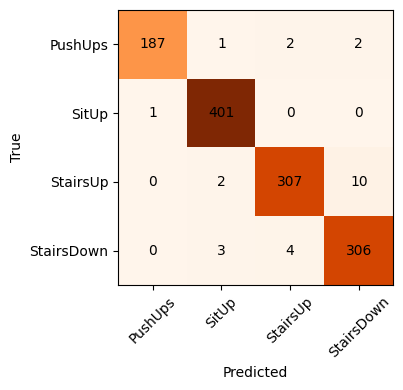

In [36]:
labels = list(activities.values())
cm = confusion_matrix(y_test, pred, labels=labels)
figure(figsize=(5, 4))
plt.imshow(cm, cmap="Oranges")
plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

confusion matrix